<a href="https://colab.research.google.com/github/AdityaJare/ML-PRojects/blob/main/age_gender_estimation_vgg16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 10.4 MB/s eta 0:00:00


In [10]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [11]:
!kaggle datasets download -d moritzm00/utkface-cropped -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/moritzm00/utkface-cropped
License(s): unknown
100% 116M/116M [00:07<00:00, 15.3MB/s]



In [12]:
import glob

files = glob.glob("/content/data/**/*.jpg", recursive=True)
print("images found:", len(files))
print(files[:3])

images found: 23708
['/content/data/UTKFace/24_0_2_20170116171647508.jpg.chip.jpg', '/content/data/UTKFace/24_1_0_20170116220317125.jpg.chip.jpg', '/content/data/UTKFace/45_0_0_20170117180013541.jpg.chip.jpg']


In [13]:
rows, bad = [], []
for p in files:
    name = os.path.basename(p)
    try:
        age, gender = name.split("_")[:2]
        rows.append({"path": p, "age": int(age), "gender": int(gender)})
    except Exception:
        bad.append(name)


In [14]:
import pandas as pd
df = pd.DataFrame(rows)

In [15]:
print(df.shape, "| unparsable files:", len(bad))

(23708, 3) | unparsable files: 0


In [16]:
print(df.head())

                                                path  age  gender
0  /content/data/UTKFace/24_0_2_20170116171647508...   24       0
1  /content/data/UTKFace/24_1_0_20170116220317125...   24       1
2  /content/data/UTKFace/45_0_0_20170117180013541...   45       0
3  /content/data/UTKFace/55_0_0_20170104201309249...   55       0
4  /content/data/UTKFace/34_1_0_20170117180013755...   34       1


In [17]:
print(df["age"].describe())

count    23708.000000
mean        33.303484
std         19.886112
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64


In [18]:
print(df["gender"].value_counts())

gender
0    12391
1    11317
Name: count, dtype: int64


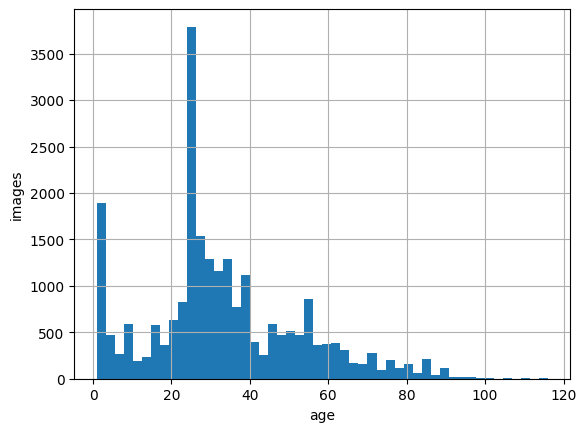

In [19]:
import matplotlib.pyplot as plt

df["age"].hist(bins=50)
plt.xlabel("age")
plt.ylabel("images")
plt.show()


In [20]:
import os

df["folder"] = df["path"].str.split("/").str[3]
print(df["folder"].value_counts())

df["fname"] = df["path"].apply(os.path.basename)
print("unique file names:", df["fname"].nunique(), "of", len(df))

folder
UTKFace    23708
Name: count, dtype: int64
unique file names: 23708 of 23708


In [21]:
df = df.drop_duplicates(subset="fname").reset_index(drop=True)

In [22]:
df.shape

(23708, 5)

In [23]:
print(df["folder"].value_counts())

folder
UTKFace    23708
Name: count, dtype: int64


In [24]:
import pandas as pd

df = df[df["folder"] == "UTKFace"]
df = df[df["gender"].isin([0, 1])].reset_index(drop=True)
print(df.shape)


(23708, 5)


In [25]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

age_band = pd.cut(df["age"], [0, 12, 25, 40, 60, 120])

train_df, temp = train_test_split(df, test_size=0.2, random_state=42, stratify=age_band)
val_ds, test_ds = train_test_split(temp, test_size=0.5, random_state=42 )

In [26]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

age_band = pd.cut(df["age"], [0, 12, 25, 40, 60, 120])
train_df, tmp = train_test_split(df, test_size=0.2, random_state=42, stratify=age_band)
val_df, test_df = train_test_split(tmp, test_size=0.5, random_state=42)
print(len(train_df), len(val_df), len(test_df))

def load(path, age, gender):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    return img, (age / 100.0, gender)

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (d["path"].values,
         d["age"].astype("float32").values,
         d["gender"].astype("float32").values))
    if shuffle:
        ds = ds.shuffle(len(d), seed=42)
    return (ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(64).prefetch(tf.data.AUTOTUNE))

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

for x, (a, g) in train_ds.take(1):
    print(x.shape, a[:3].numpy(), g[:3].numpy())

18966 2371 2371
(64, 224, 224, 3) [0.84 0.29 0.3 ] [1. 1. 0.]


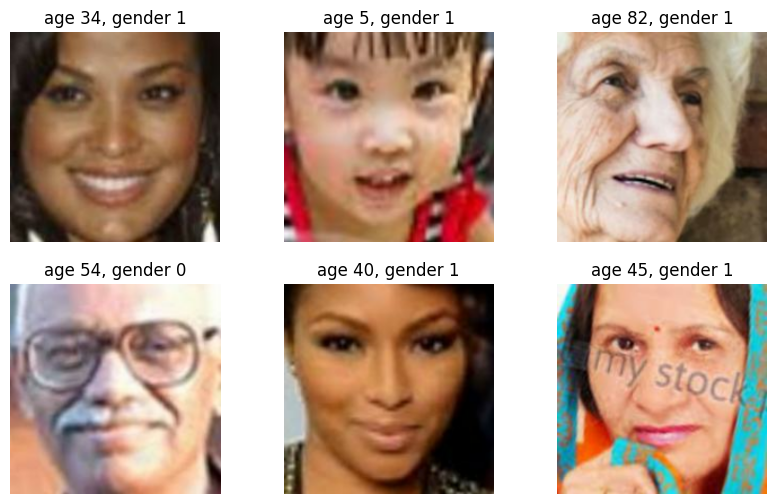

In [27]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
for x, (a, g) in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(x[i].numpy().astype("uint8"))
        plt.title(f"age {a[i].numpy()*100:.0f}, gender {int(g[i])}")
        plt.axis("off")
plt.show()

In [28]:
import tensorflow
from tensorflow import keras
conv_base = keras.applications.VGG16(
    weights="imagenet",
    include_top = False,
    input_shape=(224, 224, 3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [29]:
conv_base.trainable=True

In [30]:
set_trainable=False

for layer in conv_base.layers:
  if layer.name == "block5_conv1":
    set_trainable=True
  if set_trainable:
    layer.trainable = True
  else :
    layer.trainable = False

In [31]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 7,079,424 (27.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [32]:
for layer in conv_base.layers:
    print(layer.name, layer.trainable)

input_layer False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [33]:
from tensorflow.keras.applications.vgg16 import preprocess_input

inputs = keras.Input(shape=(224, 224, 3))
aug1 = keras.layers.RandomFlip("horizontal")(inputs)
x = keras.layers.Lambda(preprocess_input, name="vgg_preprocess")(aug1)

x = conv_base(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)

age = keras.layers.Dense(1, name="age")(x)
gender = keras.layers.Dense(1, activation="sigmoid", name="gender")(x)

model = keras.Model(inputs, [age, gender])

In [34]:
model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss={"age" : "mae", "gender" : "binary_crossentropy"},
    loss_weights={"age": 1.0, "gender": 0.5},
    metrics = {"age": "mae", "gender": "accuracy"}
)

In [35]:
callbacks =[
    keras.callbacks.ModelCheckpoint(
        "best_age_gender_vgg16.keras",
        monitor="val_age_mae",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_age_mae",
        patience=3,
        mode="min",
        restore_best_weights=True,
        verbose=1
    ),

     keras.callbacks.ReduceLROnPlateau(
        monitor="val_age_mae",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1)
]

In [36]:
history = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=callbacks)

Epoch 1/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - age_loss: 0.4739 - age_mae: 0.4739 - gender_accuracy: 0.6119 - gender_loss: 0.6922 - loss: 0.8200
Epoch 1: val_age_mae improved from None to 0.10565, saving model to best_age_gender_vgg16.keras

Epoch 1: finished saving model to best_age_gender_vgg16.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 126s 377ms/step - age_loss: 0.2072 - age_mae: 0.2074 - gender_accuracy: 0.6981 - gender_loss: 0.5661 - loss: 0.4907 - val_age_loss: 0.1064 - val_age_mae: 0.1057 - val_gender_accuracy: 0.8730 - val_gender_loss: 0.3634 - val_loss: 0.2889 - learning_rate: 1.0000e-04
Epoch 2/20
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - age_loss: 0.1182 - age_mae: 0.1182 - gender_accuracy: 0.8386 - gender_loss: 0.3633 - loss: 0.2998
Epoch 2: val_age_mae improved from 0.10565 to 0.09103, saving model to best_age_gender_vgg16.keras

Epoch 2: finished saving model to best_age_gender_vgg16.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 113s 379ms/step - age_loss: 0.1158 - age_mae: 0.1

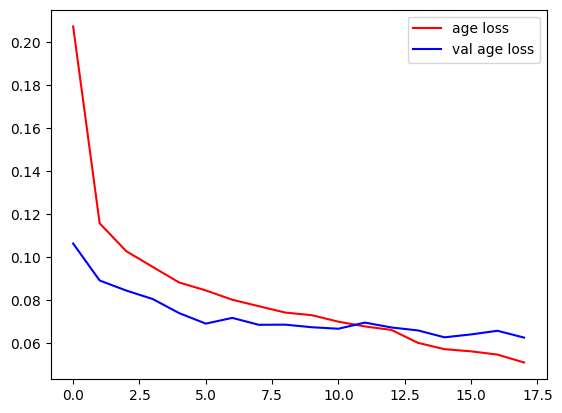

In [39]:
import matplotlib.pyplot as plt

plt.plot(history.history["age_loss"], color="red", label="age loss")
plt.plot(history.history["val_age_loss"], color="blue", label="val age loss")
plt.legend()
plt.show()

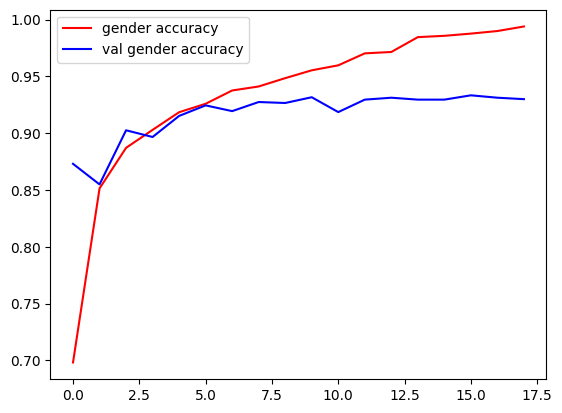

In [40]:
plt.plot(history.history["gender_accuracy"], color="red", label="gender accuracy")
plt.plot(history.history["val_gender_accuracy"], color="blue", label="val gender accuracy")
plt.legend()
plt.show()

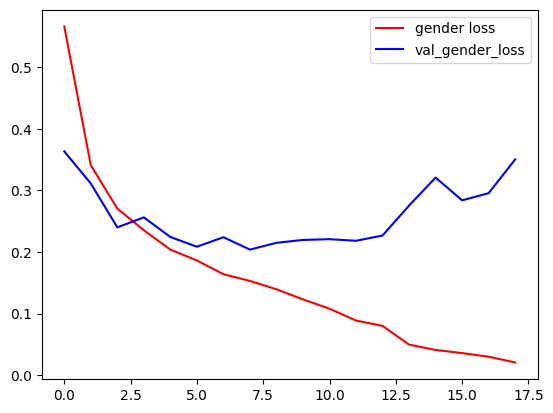

In [41]:
plt.plot(history.history["gender_loss"], color="red", label="gender loss")
plt.plot(history.history["val_gender_loss"], color="blue", label="val_gender_loss")
plt.legend()
plt.show()

In [42]:
import numpy as np
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_auc_score,
                             mean_absolute_error, mean_squared_error)

AGE_SCALE = 100

age_true, age_pred, g_true, g_prob = [], [], [], []

for x, y in test_ds:
    a_p, g_p = model.predict(x, verbose=0)
    age_pred.append(a_p.ravel())
    g_prob.append(g_p.ravel())
    if isinstance(y, dict):
        age_true.append(y["age"].numpy().ravel())
        g_true.append(y["gender"].numpy().ravel())
    else:
        age_true.append(y[0].numpy().ravel())
        g_true.append(y[1].numpy().ravel())

age_true = np.concatenate(age_true) * AGE_SCALE
age_pred = np.concatenate(age_pred) * AGE_SCALE
g_true   = np.concatenate(g_true).astype(int)
g_prob   = np.concatenate(g_prob)
g_pred   = (g_prob > 0.5).astype(int)

In [43]:
print("Gender accuracy:", accuracy_score(g_true, g_pred))
print("Gender ROC-AUC :", roc_auc_score(g_true, g_prob))
print(classification_report(g_true, g_pred, target_names=["Male", "Female"]))
print(confusion_matrix(g_true, g_pred))

Gender accuracy: 0.9333614508646141
Gender ROC-AUC : 0.9798416273125452
              precision    recall  f1-score   support

        Male       0.95      0.93      0.94      1249
      Female       0.92      0.94      0.93      1122

    accuracy                           0.93      2371
   macro avg       0.93      0.93      0.93      2371
weighted avg       0.93      0.93      0.93      2371

[[1156   93]
 [  65 1057]]


In [44]:
print("Age MAE  (years):", mean_absolute_error(age_true, age_pred))
print("Age RMSE (years):", np.sqrt(mean_squared_error(age_true, age_pred)))
print("Within 5 years :", np.mean(np.abs(age_true - age_pred) <= 5))
print("Within 10 years:", np.mean(np.abs(age_true - age_pred) <= 10))

Age MAE  (years): 6.4674577713012695
Age RMSE (years): 9.259482394885332
Within 5 years : 0.5482918599746942
Within 10 years: 0.7950231969633066


In [45]:
from google.colab import files as colab_files

up = colab_files.upload()
path = list(up.keys())[0]
print(path)

Saving 13_1_0_20170104005742384.jpg.chip.jpg to 13_1_0_20170104005742384.jpg.chip.jpg
13_1_0_20170104005742384.jpg.chip.jpg


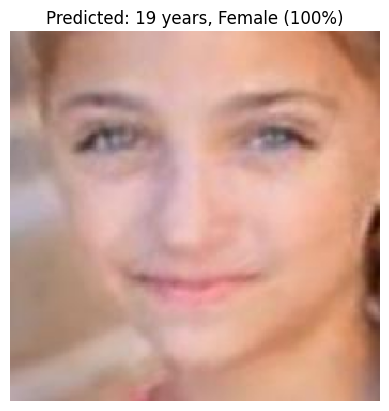

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

AGE_SCALE = 100

img = image.load_img(path, target_size=(224, 224))
arr = np.expand_dims(image.img_to_array(img), axis=0)

age_p, gender_p = model.predict(arr, verbose=0)
age = float(age_p[0][0]) * AGE_SCALE
g = float(gender_p[0][0])
gender = "Female" if g > 0.5 else "Male"
conf = g if g > 0.5 else 1 - g

plt.imshow(img); plt.axis("off")
plt.title(f"Predicted: {age:.0f} years, {gender} ({conf:.0%})")
plt.show()

In [47]:
up = colab_files.upload()
path = list(up.keys())[0]
print(path)

Saving 16_1_0_20170116204045849.jpg.chip.jpg to 16_1_0_20170116204045849.jpg.chip.jpg
16_1_0_20170116204045849.jpg.chip.jpg


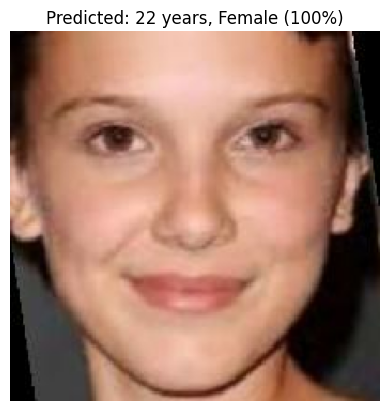

In [48]:
AGE_SCALE = 100

img = image.load_img(path, target_size=(224, 224))
arr = np.expand_dims(image.img_to_array(img), axis=0)

age_p, gender_p = model.predict(arr, verbose=0)
age = float(age_p[0][0]) * AGE_SCALE
g = float(gender_p[0][0])
gender = "Female" if g > 0.5 else "Male"
conf = g if g > 0.5 else 1 - g

plt.imshow(img); plt.axis("off")
plt.title(f"Predicted: {age:.0f} years, {gender} ({conf:.0%})")
plt.show()

In [57]:
up = colab_files.upload()
path = list(up.keys())[0]
print(path)

Saving 101_0_0_20170112213500903.jpg.chip.jpg to 101_0_0_20170112213500903.jpg.chip.jpg
101_0_0_20170112213500903.jpg.chip.jpg


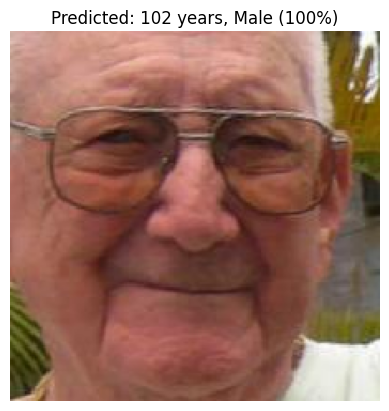

In [58]:
AGE_SCALE = 100

img = image.load_img(path, target_size=(224, 224))
arr = np.expand_dims(image.img_to_array(img), axis=0)

age_p, gender_p = model.predict(arr, verbose=0)
age = float(age_p[0][0]) * AGE_SCALE
g = float(gender_p[0][0])
gender = "Female" if g > 0.5 else "Male"
conf = g if g > 0.5 else 1 - g

plt.imshow(img); plt.axis("off")
plt.title(f"Predicted: {age:.0f} years, {gender} ({conf:.0%})")
plt.show()

In [62]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [63]:
import shutil
shutil.copy("best_age_gender_vgg16.keras",
            "/content/drive/MyDrive/best_age_gender_vgg16.keras")

'/content/drive/MyDrive/best_age_gender_vgg16.keras'

In [64]:
import os
p = "/content/drive/MyDrive/best_age_gender_vgg16.keras"
print(os.path.exists(p), round(os.path.getsize(p) / 1e6, 1), "MB")

True 115.6 MB
